# asthma_GSE152004 — sRGES pipeline (drug summarisation after CS) vs TSR/LMM pipeline

**Caveat on the evaluation:** labels are the curated ones (section 7): 18 approved drugs against 2
negatives (pioglitazone and moxifloxacin, trials stopped for safety; no asthma trial was stopped for
lack of efficacy). The AUROCs of section 7 only describe where the two negatives fall.

Two ways of turning LINCS L1000 drug signatures into one score per drug, on the same asthma disease
signature (GSE152004, nasal airway epithelium, 440 asthmatic vs 254 healthy controls):

| | **TSR/LMM pipeline** (used so far for asthma, IPF, ALS) | **sRGES pipeline** (Chen 2017 / OCTAD) |
|---|---|---|
| drug signatures | level-3 L1000, collapsed per drug **before** CS by a linear mixed model (cell line `all`) | level-5 landmark signatures, **one per instance** (drug × cell line × dose × time), 71 cell lines |
| CS | one per drug (pooled `6h_24h` used here) | one per instance |
| per-drug score | the CS itself | collapse **after** CS: `sRGES_weighted` (cell lines weighted by CCLE similarity to the asthma samples), `sRGES_unweighted`, `best` (most negative instance) |
| drug universe | 3,221 compounds | 12,442 compounds (DEG; BRD ids with the same L1000 name pooled) |

Sign convention for every score: **more negative = stronger reversal = better candidate**.

Inputs (all produced by the case-study scripts in `src/case_studies/asthma_GSE152004/`):
`02_cell_line_weights.py` (weights), `03_srges_per_drug.py` (per-drug sRGES table),
`04_repodb_auroc.py` (labelled-drug scores and AUROC). TSR runs via `loader.load_cs_run(drug_run_id='all')`.

**MITHrIL configurations (`mith`, `mith_LM`, `mith_pw`) of the sRGES pipeline are pending**: MITHrIL
is still running on the drug instances. Every section below is written for all configurations and
fills in automatically when `03_`/`04_` are re-run after MITHrIL; until then only configurations
with CS runs on all 71 cell lines are shown (currently `DEG`). In this route `DEG_LM` = `DEG`
(the drug signatures are landmark-only).

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option('display.width', 180)
pd.set_option('display.max_columns', 30)
plt.rcParams.update({'axes.grid': True, 'grid.color': '0.75', 'grid.linestyle': '--', 'grid.linewidth': .6})
BLUE, RED = '#1f4e9c', '#c0392b'

DISEASE = 'asthma_GSE152004'
def _find_root(start):
    p = start
    for _ in range(8):
        if os.path.isdir(os.path.join(p, 'connectivity_score', 'input')):
            return p
        p = os.path.dirname(p)
    return None
NETCOS_ROOT = _find_root(os.getcwd())
sys.path.insert(0, os.path.join(NETCOS_ROOT, 'src'))
from loader import load_cs_run

OUT = os.path.join(NETCOS_ROOT, 'other_outputs', 'case_studies', DISEASE)
IMG_DIR = os.path.join(NETCOS_ROOT, 'imgs', 'case_studies', DISEASE)
os.makedirs(IMG_DIR, exist_ok=True)
N_LINES = 71

srges = pd.read_csv(os.path.join(OUT, f'{DISEASE}_srges_per_drug.tsv'), sep='\t')
runs_used = pd.read_csv(os.path.join(OUT, f'{DISEASE}_srges_cs_runs_used.tsv'), sep='\t')
weights = pd.read_csv(os.path.join(OUT, f'{DISEASE}_cell_line_weights.tsv'), sep='\t')
lab_scores = pd.read_csv(os.path.join(OUT, f'{DISEASE}_repodb_labelled_drug_scores.tsv'), sep='\t')
auroc = pd.read_csv(os.path.join(OUT, f'{DISEASE}_repodb_auroc_srges.tsv'), sep='\t')

complete = runs_used.groupby('config')['cell_line'].nunique()
CONFIGS = [c for c in ['DEG', 'mith', 'mith_LM', 'mith_pw'] if complete.get(c, 0) == N_LINES]
PENDING = [c for c in ['DEG', 'mith', 'mith_LM', 'mith_pw'] if c not in CONFIGS]
COLLAPSES = ['sRGES_weighted', 'sRGES_unweighted', 'best']
print('cell lines with a CS run per configuration:', complete.to_dict())
print('shown:', CONFIGS, '| pending (MITHrIL running):', PENDING)

cell lines with a CS run per configuration: {'DEG': 71, 'mith': 37, 'mith_LM': 37, 'mith_pw': 37}
shown: ['DEG'] | pending (MITHrIL running): ['mith', 'mith_LM', 'mith_pw']


## 1. TSR/LMM drug-collapsed runs (reference)

The most recent `bin_chen` run of each configuration on drug input `all`, pooled `6h_24h` rows,
drug key = L1000 name (lower case, alphanumerics only).

In [2]:
TSR_CONFIGS = {'DEG': (0, 0, 0), 'DEG_LM': (0, 1, 0), 'mith': (1, 0, 0), 'mith_LM': (1, 1, 0), 'mith_pw': (1, 0, 1)}
key = lambda s: s.astype(str).str.lower().str.replace(r'[^a-z0-9]', '', regex=True)
tsr = {}
for lab, (m, lm, pw) in TSR_CONFIGS.items():
    df, path, run_id = load_cs_run(disease=DISEASE, landmark_disease=False, drug_run_id='all', mith=m, cs_on_LM=lm,
                                   CS_ON_PATHWAYS=pw, CS_METHOD='bin_chen', verbose=False)
    p = df[df['pert_id'].astype(str).str.endswith('_6h_24h')].copy()
    p['k'] = key(p['pert_id'].str[:-len('_6h_24h')])
    tsr[lab] = p.groupby('k')['connectivity_score'].mean()
    print(f'{lab:8s} {run_id}  drugs {len(tsr[lab])}')

DEG      27_10_2026_18_08_DEG_bin_chen_connectivity_score  drugs 3221
DEG_LM   27_10_2026_18_11_DEG_LM_bin_chen_connectivity_score  drugs 3221
mith     27_10_2026_18_12_mith_bin_chen_connectivity_score  drugs 3221
mith_LM  27_10_2026_18_17_mith_LM_bin_chen_connectivity_score  drugs 3221
mith_pw  27_10_2026_18_11_mith_pw_bin_chen_connectivity_score  drugs 3221


## 2. Coverage of the sRGES pipeline

In [3]:
s = srges[srges['config'].isin(CONFIGS)].copy()
s['k'] = key(s['pert_iname'])
cov = s.groupby(['config', 'collapse']).agg(n_drugs=('pert_iname', 'size'), compounds_several_BRD=('n_pert_ids', lambda x: int((x > 1).sum())),
        median_instances=('n_instances', 'median'), drugs_1_instance=('n_instances', lambda x: int((x == 1).sum())),
        median_cell_lines=('n_cell_lines', 'median'), drugs_1_cell_line=('n_cell_lines', lambda x: int((x == 1).sum())))
display(cov)
for c in CONFIGS:
    names = set(s.loc[(s.config == c) & (s.collapse == 'sRGES_unweighted'), 'k'])
    t = set(tsr[c].index)
    print(f'{c}: sRGES compounds {len(names)}, TSR {len(t)}, shared {len(names & t)}, TSR-only {len(t - names)}')
lost = 1 - s.loc[s.collapse == 'sRGES_weighted'].groupby('config').size() / s.loc[s.collapse == 'sRGES_unweighted'].groupby('config').size()
print('share of compounds lost by the weighted sRGES (only on lines without a CCLE weight):', lost.round(3).to_dict())

n_drugs  compounds_several_BRD  median_instances  drugs_1_instance  median_cell_lines  drugs_1_cell_line
config collapse                                                                                                                  
DEG    best                12442                    426               2.0              5041                2.0               6075
       sRGES_unweighted    12442                    426               2.0              5041                2.0               6075
       sRGES_weighted      12168                    424               2.0              5072                1.0               6159

DEG: sRGES compounds 12440, TSR 3221, shared 3076, TSR-only 145
share of compounds lost by the weighted sRGES (only on lines without a CCLE weight): {'DEG': 0.022}


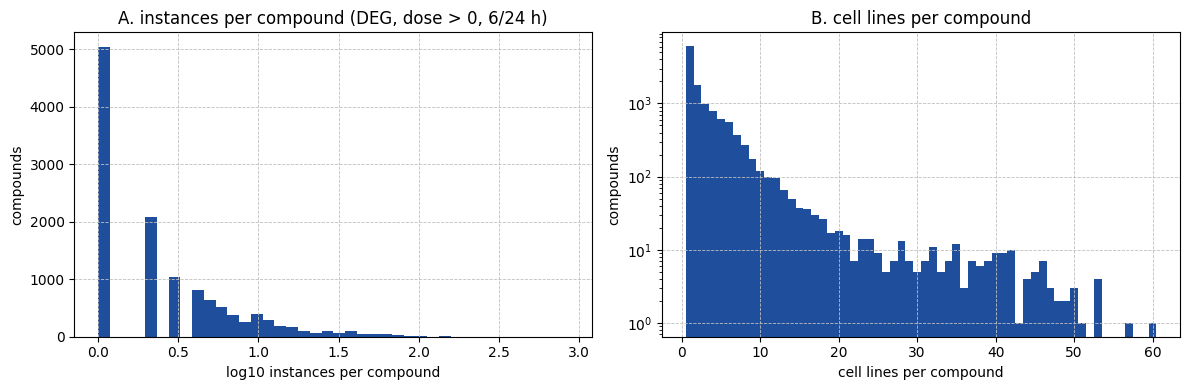

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
u = s[(s.collapse == 'sRGES_unweighted') & (s.config == CONFIGS[0])]
ax[0].hist(np.log10(u['n_instances']), bins=40, color=BLUE)
ax[0].set_xlabel('log10 instances per compound'); ax[0].set_ylabel('compounds')
ax[0].set_title(f'A. instances per compound ({CONFIGS[0]}, dose > 0, 6/24 h)')
ax[1].hist(u['n_cell_lines'], bins=np.arange(0.5, u['n_cell_lines'].max() + 1.5), color=BLUE)
ax[1].set_xlabel('cell lines per compound'); ax[1].set_ylabel('compounds'); ax[1].set_yscale('log')
ax[1].set_title('B. cell lines per compound')
plt.tight_layout(); plt.savefig(os.path.join(IMG_DIR, f'{DISEASE}_srges_coverage.png'), dpi=120); plt.show()

## 3. Score distributions

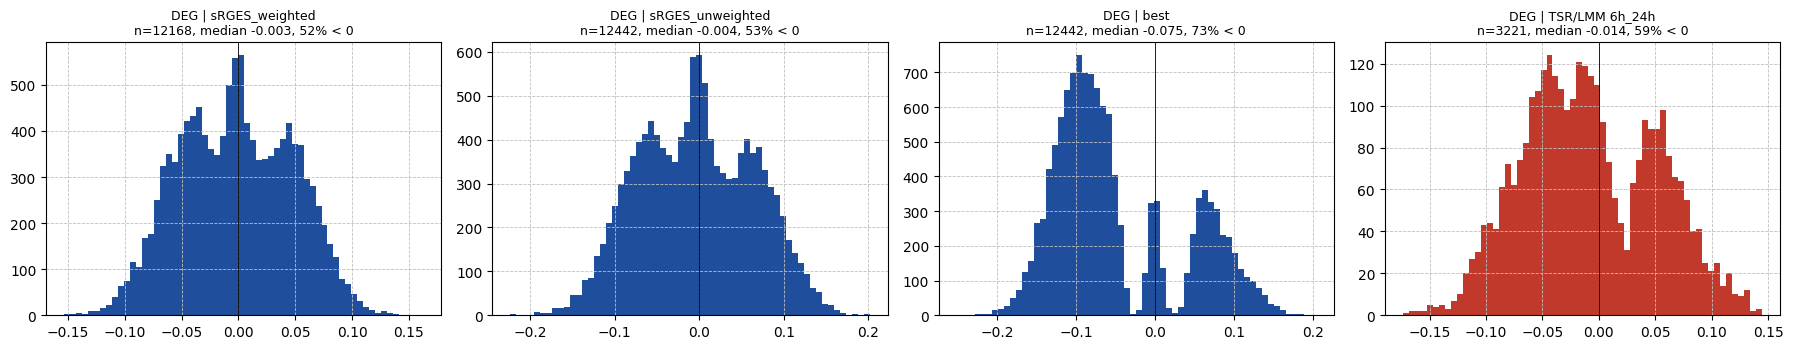

In [5]:
fig, axes = plt.subplots(len(CONFIGS), 4, figsize=(18, 3.6 * len(CONFIGS)), squeeze=False)
for i, c in enumerate(CONFIGS):
    for j, coll in enumerate(COLLAPSES):
        v = s[(s.config == c) & (s.collapse == coll)]['score']
        a = axes[i, j]; a.hist(v, bins=60, color=BLUE)
        a.axvline(0, color='k', lw=.6)
        a.set_title(f'{c} | {coll}\nn={len(v)}, median {v.median():+.3f}, {100 * (v < 0).mean():.0f}% < 0', fontsize=9)
    v = tsr[c]; a = axes[i, 3]; a.hist(v, bins=60, color=RED); a.axvline(0, color='k', lw=.6)
    a.set_title(f'{c} | TSR/LMM 6h_24h\nn={len(v)}, median {v.median():+.3f}, {100 * (v < 0).mean():.0f}% < 0', fontsize=9)
plt.tight_layout(); plt.savefig(os.path.join(IMG_DIR, f'{DISEASE}_srges_score_distributions.png'), dpi=120); plt.show()

## 4. Agreement between collapses and with the TSR pipeline

Spearman correlation of per-compound scores, on the compounds present in both (sRGES compounds
matched to TSR by L1000 name; several compounds with the same name are averaged).

,config,x,y,n,spearman
0,DEG,sRGES_weighted,sRGES_unweighted,12166,0.982
1,DEG,sRGES_weighted,best,12166,0.708
2,DEG,sRGES_weighted,TSR,3053,0.477
3,DEG,sRGES_unweighted,best,12440,0.720
4,DEG,sRGES_unweighted,TSR,3076,0.519
5,DEG,best,TSR,3076,0.308


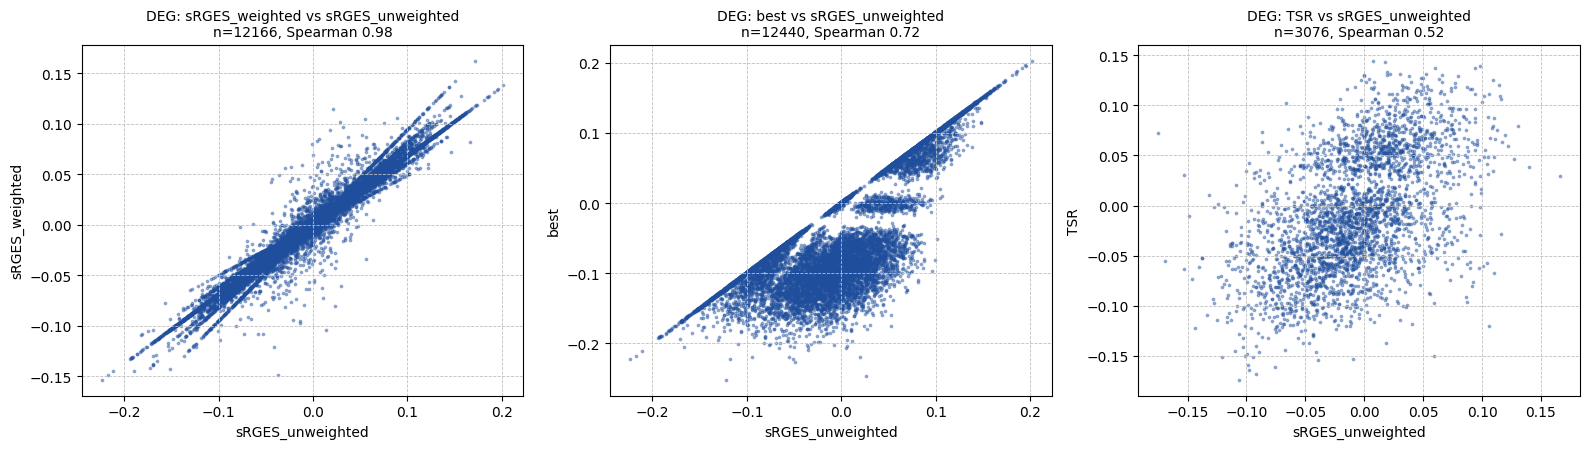

In [6]:
rows = []
for c in CONFIGS:
    piv = s[s.config == c].groupby(['k', 'collapse'])['score'].mean().unstack()
    piv['TSR'] = tsr[c].reindex(piv.index)
    cols = COLLAPSES + ['TSR']
    for a_ in range(len(cols)):
        for b_ in range(a_ + 1, len(cols)):
            d = piv[[cols[a_], cols[b_]]].dropna()
            rows.append({'config': c, 'x': cols[a_], 'y': cols[b_], 'n': len(d),
                         'spearman': stats.spearmanr(d.iloc[:, 0], d.iloc[:, 1]).statistic})
agree = pd.DataFrame(rows); display(agree.round(3))

c = CONFIGS[0]
piv = s[s.config == c].groupby(['k', 'collapse'])['score'].mean().unstack(); piv['TSR'] = tsr[c].reindex(piv.index)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
for a, (x, y) in zip(ax, [('sRGES_unweighted', 'sRGES_weighted'), ('sRGES_unweighted', 'best'), ('sRGES_unweighted', 'TSR')]):
    d = piv[[x, y]].dropna()
    a.scatter(d[x], d[y], s=3, alpha=.4, color=BLUE)
    a.set_xlabel(x); a.set_ylabel(y)
    a.set_title(f'{c}: {y} vs {x}\nn={len(d)}, Spearman {stats.spearmanr(d[x], d[y]).statistic:.2f}', fontsize=10)
plt.tight_layout(); plt.savefig(os.path.join(IMG_DIR, f'{DISEASE}_srges_agreement.png'), dpi=120); plt.show()

## 5. Top-ranked compounds

In [7]:
TOP = 20
for c in CONFIGS:
    tabs = {}
    for coll in COLLAPSES:
        d = s[(s.config == c) & (s.collapse == coll)].sort_values('score').head(TOP)
        tabs[coll] = [f'{n} ({v:+.3f}, {int(k)} inst)' for n, v, k in zip(d.pert_iname, d.score, d.n_instances)]
    t = tsr[c].sort_values().head(TOP)
    tabs['TSR/LMM 6h_24h'] = [f'{n} ({v:+.3f})' for n, v in t.items()]
    print(f'=== {c} ==='); display(pd.DataFrame(tabs, index=range(1, TOP + 1)))

MIN_INST = 3
for c in CONFIGS:
    tabs = {}
    for coll in COLLAPSES:
        d = s[(s.config == c) & (s.collapse == coll) & (s.n_instances >= MIN_INST)].sort_values('score').head(TOP)
        tabs[coll] = [f'{n} ({v:+.3f}, {int(k)} inst, {int(l)} lines)' for n, v, k, l in zip(d.pert_iname, d.score, d.n_instances, d.n_cell_lines)]
    print(f'=== {c}, compounds with >= {MIN_INST} instances ==='); display(pd.DataFrame(tabs, index=range(1, TOP + 1)))
u = s[(s.config == CONFIGS[0]) & (s.collapse == 'sRGES_unweighted')]
for k, g in u.groupby(pd.cut(u.n_instances, [0, 1, 2, 5, 20, 10**6], labels=['1', '2', '3-5', '6-20', '>20']), observed=False):
    print(f'instances {k:>5s}: n={len(g):5d}  score sd {g.score.std():.3f}  share in top 1% {100 * (g.score <= u.score.quantile(.01)).mean():.1f}%')

=== DEG ===


,sRGES_weighted,sRGES_unweighted,best,TSR/LMM 6h_24h
1,"BRD-K46359800 (-0.153, 1 inst)","BRD-K46359800 (-0.224, 1 inst)","BRD-K67519589 (-0.252, 5 inst)",homoharringtonine (-0.174)
2,"BRD-K38493271 (-0.149, 1 inst)","BRD-K38493271 (-0.218, 1 inst)","BRD-A95937159 (-0.246, 11 inst)",calyculin (-0.168)
3,"BRD-K44812652 (-0.149, 1 inst)","BRD-K31538032 (-0.212, 1 inst)","BRD-K58547240 (-0.227, 9 inst)",safrolglycol (-0.164)
4,"BRD-K22458275 (-0.145, 1 inst)","BRD-K10894258 (-0.194, 1 inst)","BRD-K46359800 (-0.222, 1 inst)",vx702 (-0.161)
5,"BRD-K31538032 (-0.145, 1 inst)","BRD-K56945204 (-0.193, 1 inst)","BRD-K03176945 (-0.222, 6 inst)",qlx138 (-0.159)
6,"BRD-K82414981 (-0.143, 1 inst)","BRD-K53437983 (-0.193, 1 inst)","BRD-K53816294 (-0.222, 3 inst)",vincamine (-0.154)
7,"clopamide (-0.141, 1 inst)","BRD-K70751797 (-0.192, 1 inst)","sulfafurazole (-0.220, 8 inst)",brdk71427192 (-0.153)
8,"BRD-K64607642 (-0.139, 1 inst)","BRD-K82794234 (-0.192, 1 inst)","emetine (-0.220, 115 inst)",emetine (-0.151)
9,"PSH-022 (-0.138, 1 inst)","BRD-K28947191 (-0.191, 1 inst)","BRD-K51454562 (-0.220, 2 inst)",cephaeline (-0.151)
10,"BRD-K89840812 (-0.138, 1 inst)","BRD-K22458275 (-0.190, 1 inst)","BRD-K38493271 (-0.218, 1 inst)",hydrocotarnine (-0.151)


=== DEG, compounds with >= 3 instances ===


,sRGES_weighted,sRGES_unweighted,best
1,"BRD-K83720640 (-0.115, 4 inst, 1 lines)","BRD-K83720640 (-0.167, 4 inst, 1 lines)","BRD-K67519589 (-0.252, 5 inst, 5 lines)"
2,"BRD-K64985742 (-0.105, 4 inst, 3 lines)","BRD-K70880645 (-0.152, 3 inst, 1 lines)","BRD-A95937159 (-0.246, 11 inst, 8 lines)"
3,"BRD-K70880645 (-0.104, 3 inst, 1 lines)","BRD-K64985742 (-0.146, 4 inst, 3 lines)","BRD-K58547240 (-0.227, 9 inst, 7 lines)"
4,"SA-83851 (-0.104, 4 inst, 2 lines)","BRD-K81224183 (-0.145, 3 inst, 1 lines)","BRD-K03176945 (-0.222, 6 inst, 5 lines)"
5,"SA-103150 (-0.103, 3 inst, 1 lines)","BRD-K75418563 (-0.131, 7 inst, 3 lines)","BRD-K53816294 (-0.222, 3 inst, 3 lines)"
6,"SA-427228 (-0.100, 3 inst, 1 lines)","BRD-K34332553 (-0.127, 4 inst, 3 lines)","sulfafurazole (-0.220, 8 inst, 8 lines)"
7,"BRD-K81224183 (-0.100, 3 inst, 1 lines)","BRD-K68783079 (-0.126, 3 inst, 3 lines)","emetine (-0.220, 115 inst, 49 lines)"
8,"BRD-K64885524 (-0.099, 3 inst, 3 lines)","BRD-K64885524 (-0.125, 4 inst, 4 lines)","kynuramine (-0.209, 6 inst, 6 lines)"
9,"SA-1459167 (-0.098, 4 inst, 1 lines)","PP242 (-0.124, 5 inst, 1 lines)","mesoridazine (-0.207, 18 inst, 14 lines)"
10,"BRD-K63399564 (-0.094, 4 inst, 4 lines)","SA-83851 (-0.124, 4 inst, 2 lines)","BRD-K54822214 (-0.206, 9 inst, 8 lines)"


instances     1: n= 5041  score sd 0.086  share in top 1% 2.2%
instances     2: n= 2090  score sd 0.067  share in top 1% 0.5%
instances   3-5: n= 2472  score sd 0.052  share in top 1% 0.1%
instances  6-20: n= 2307  score sd 0.040  share in top 1% 0.0%
instances   >20: n=  532  score sd 0.034  share in top 1% 0.0%


## 6. Effect of the CCLE cell-line weight

Weighted sRGES multiplies every instance by `cor / max(cor)` (cor = median correlation of the line
with the asthmatic samples) and leaves out the 13 lines without CCLE expression.

In [8]:
for c in CONFIGS:
    w = s[(s.config == c) & (s.collapse == 'sRGES_weighted')].set_index('pert_iname')['score']
    u = s[(s.config == c) & (s.collapse == 'sRGES_unweighted')].set_index('pert_iname')['score']
    d = pd.concat([u.rename('unweighted'), w.rename('weighted')], axis=1).dropna()
    ru, rw = d['unweighted'].rank(pct=True), d['weighted'].rank(pct=True)
    print(f'{c}: n={len(d)}, Spearman {stats.spearmanr(d.unweighted, d.weighted).statistic:.3f}; '
          f'median |percentile shift| {100 * (ru - rw).abs().median():.1f} points; '
          f'top-100 overlap {len(set(d.unweighted.nsmallest(100).index) & set(d.weighted.nsmallest(100).index))}/100')
display(weights.sort_values('cor', ascending=False).head(10).round(3))

DEG: n=12168, Spearman 0.982; median |percentile shift| 1.6 points; top-100 overlap 64/100


,lincs_cell_id,cor
0,NCIH596,0.562
1,CL34,0.556
2,NCIH508,0.539
3,HT115,0.538
5,SNU1040,0.536
4,SNUC4,0.536
6,HT29,0.533
8,COV644,0.529
7,SW948,0.528
9,SKBR3,0.525


## 7. Labelled asthma drugs (curated labels)

Labels from `repodb_signature_lincs_pairs_stop_reason.tsv` (C0004096), as written by `04_repodb_auroc.py`:
- **positives:** the 18 repoDB approved pairs;
- **negatives:** not-approved pairs with a trial stopped for efficacy or safety (`pair_stop_class`):
  pioglitazone and moxifloxacin, both safety. Second negative set: only stops in trials that dosed
  participants (`clinical_stop_enrolled`): pioglitazone;
- **excluded:** the other 12 not-approved pairs (non-clinical or unknown stop) and the 5 conflict pairs.

With two negatives (or one) the AUROC is the share of approved drugs ranked above them: it describes
where the negatives fall, it does not estimate a separation.
Percentile = share of all compounds of that route/configuration with a more negative score (lower =
stronger reversal). Second table: percentiles.

In [9]:
ls = lab_scores[lab_scores.config.isin(CONFIGS)].copy()
ls['drug_name'] = ls['drug_name'].fillna(ls['drugbank_id'])
for c in CONFIGS:
    ref = {('per_instance_all_lines', coll): s[(s.config == c) & (s.collapse == coll)]['score'] for coll in COLLAPSES}
    ref[('tsr_lmm_collapsed', 'tsr_lmm_6h_24h')] = tsr[c]
    for (route, coll), v in ref.items():
        m = (ls.config == c) & (ls.route == route) & (ls.collapse == coll)
        ls.loc[m, 'percentile'] = ls.loc[m, 'score'].apply(lambda x: np.nan if pd.isna(x) else 100 * (v < x).mean())
tab = ls.pivot_table(index=['label', 'drug_name'], columns=['route', 'collapse'], values='score', aggfunc='first')
inst = ls[(ls.route == 'per_instance_all_lines') & (ls.collapse == 'sRGES_unweighted')].groupby(['label', 'drug_name'])['n_instances'].first()
tab[('instances', '')] = inst
display(tab.round(3).sort_index())
display(ls.pivot_table(index=['label', 'drug_name'], columns=['route', 'collapse'], values='percentile', aggfunc='first').round(1).sort_index())

route                               per_instance_all_lines                                 tsr_lmm_collapsed instances
collapse                                              best sRGES_unweighted sRGES_weighted    tsr_lmm_6h_24h          
label    drug_name                                                                                                    
approved acefylline                                  0.040            0.040          0.031               NaN       1.0
         beclometasone dipropionate                 -0.118            0.015          0.005             0.087      15.0
         betamethasone                              -0.087            0.034          0.024             0.047      25.0
         cromoglicic acid                           -0.059           -0.059         -0.045               NaN       1.0
         diprophylline                               0.016            0.016          0.008               NaN       1.0
         flunisolide                                -0.148            0.015          0.008             0.001      20.0
         hydrocortisone                              0.002            0.065          0.048             0.028      46.0
         ibudilast                                  -0.099            0.056          0.062             0.052       6.0
         methylprednisolone                         -0.101           -0.048         -0.033               NaN       5.0
         norepinephrine                             -0.075            0.010          0.024            -0.003       7.0
         orciprenaline                              -0.113            0.031          0.027               NaN      10.0
         ozagrel                                    -0.080           -0.000         -0.003            -0.025       9.0
         pranlukast                                  0.045            0.067          0.054               NaN       2.0
         terbutaline                                -0.068            0.042          0.029               NaN       4.0
         theophylline                               -0.095           -0.019         -0.019               NaN       2.0
         tranilast                                  -0.106           -0.009         -0.008             0.011      13.0
         triamcinolone                              -0.121            0.013          0.008             0.047      31.0
         zafirlukast                                -0.141           -0.037         -0.022               NaN       3.0
negative moxifloxacin                               -0.130           -0.034         -0.014            -0.080       7.0
         pioglitazone                               -0.097            0.014          0.009            -0.045       8.0

route                               per_instance_all_lines                                 tsr_lmm_collapsed
collapse                                              best sRGES_unweighted sRGES_weighted    tsr_lmm_6h_24h
label    drug_name                                                                                          
approved acefylline                                   77.1             70.9           71.3               NaN
         beclometasone dipropionate                   18.4             61.3           57.0              94.5
         betamethasone                                40.9             68.8           67.9              78.1
         cromoglicic acid                             60.4             24.0           22.2               NaN
         diprophylline                                76.4             62.0           58.9               NaN
         flunisolide                                   5.4             61.5           59.0              60.0
         hydrocortisone                               74.1             81.3           81.8              69.3
         ibudilast                                    31.7             77.5           89.5              80.4
         methylprednisolone                           30.2             29.0           30.6               NaN
         norepinephrine                               49.4             59.1           67.9              57.3
         orciprenaline                                21.3             67.8           69.2               NaN
         ozagrel                                      45.8             52.7           49.5              42.3
         pranlukast                                   78.0             82.2           85.1               NaN
         terbutaline                                  54.7             71.5           70.5               NaN
         theophylline                                 35.2             41.8           38.6               NaN
         tranilast                                    26.8             47.1           45.2              64.9
         triamcinolone                                17.0             60.9           59.0              77.8
         zafirlukast                                   7.2             34.2           36.8               NaN
negative moxifloxacin                                 11.7             35.4           41.4              11.1
         pioglitazone                                 33.2             61.2           59.4              29.7

,negative_set,route,config,collapse,drug_set,n_approved,n_negative,AUROC,CI95_low,CI95_high,p_MannWhitney,sRGES_counterpart
0,stop_efficacy_safety,per_instance_all_lines,DEG,best,all_scored,18,2,0.278,0.000,0.611,0.379,available
1,stop_efficacy_safety,per_instance_all_lines,DEG,best,matched_to_tsr,9,2,0.333,0.000,0.778,0.582,available
2,stop_efficacy_safety,per_instance_all_lines,DEG,sRGES_unweighted,all_scored,18,2,0.306,0.056,0.611,0.442,available
3,stop_efficacy_safety,per_instance_all_lines,DEG,sRGES_unweighted,matched_to_tsr,9,2,0.222,0.000,0.667,0.327,available
4,stop_efficacy_safety,per_instance_all_lines,DEG,sRGES_weighted,all_scored,18,2,0.389,0.111,0.722,0.674,available
5,stop_efficacy_safety,per_instance_all_lines,DEG,sRGES_weighted,matched_to_tsr,9,2,0.278,0.000,0.778,0.436,available
6,stop_efficacy_safety,tsr_lmm_collapsed,DEG,tsr_lmm_6h_24h,all_scored,9,2,0.000,0.000,0.000,0.036,available
7,stop_efficacy_safety,tsr_lmm_collapsed,DEG_LM,tsr_lmm_6h_24h,all_scored,9,2,0.222,0.000,0.556,0.327,pending (MITHrIL)
8,stop_efficacy_safety,tsr_lmm_collapsed,mith,tsr_lmm_6h_24h,all_scored,9,2,0.167,0.000,0.556,0.218,pending (MITHrIL)
9,stop_efficacy_safety,tsr_lmm_collapsed,mith_LM,tsr_lmm_6h_24h,all_scored,9,2,0.111,0.000,0.333,0.145,pending (MITHrIL)


matched_to_tsr = the labelled drugs scored by both pipelines: the like-for-like comparison.


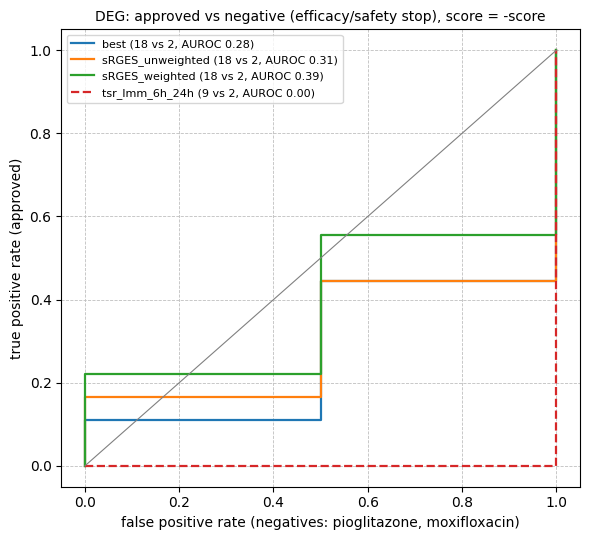

In [10]:
a = auroc[(auroc.config.isin(CONFIGS)) | (auroc.route == 'tsr_lmm_collapsed')].copy()
NEG_SET = 'stop_efficacy_safety'                      # primary negative set (pioglitazone, moxifloxacin)
a['sRGES_counterpart'] = np.where(a.config.isin(CONFIGS), 'available', 'pending (MITHrIL)')
display(a.round(3))
print('matched_to_tsr = the labelled drugs scored by both pipelines: the like-for-like comparison.')

from sklearn.metrics import roc_curve
fig, ax = plt.subplots(figsize=(6, 5.5))
for (route, c, coll), d in ls.groupby(['route', 'config', 'collapse']):
    if c != CONFIGS[0]:
        continue
    d = d.dropna(subset=['score'])
    fpr, tpr, _ = roc_curve((d.label == 'approved').astype(int), -d.score)
    r = a[(a.negative_set == NEG_SET) & (a.drug_set == 'all_scored') & (a.route == route) & (a.config == c) & (a.collapse == coll)].iloc[0]
    ax.plot(fpr, tpr, lw=1.6, ls='--' if route.startswith('tsr') else '-',
            label=f'{coll} ({int(r.n_approved)} vs {int(r.n_negative)}, AUROC {r.AUROC:.2f})')
ax.plot([0, 1], [0, 1], color='grey', lw=.8)
ax.set_xlabel('false positive rate (negatives: pioglitazone, moxifloxacin)'); ax.set_ylabel('true positive rate (approved)')
ax.set_title(f'{CONFIGS[0]}: approved vs negative (efficacy/safety stop), score = -score', fontsize=10); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(IMG_DIR, f'{DISEASE}_srges_repodb_auroc.png'), dpi=120); plt.show()

## 8. MITHrIL configurations — placeholder

`mith`, `mith_LM`, `mith_pw` of the sRGES pipeline appear in every section above once
`03_srges_per_drug.py` and `04_repodb_auroc.py` are re-run after MITHrIL has processed all 71 cell
lines (`logs/mithril_all_cell_lines_05_11_2026.log`) and the CS runs of those configurations exist for
every line (`run_cs_all_cell_lines.py`).

In [11]:
print('pending configurations:', PENDING or 'none')

pending configurations: ['mith', 'mith_LM', 'mith_pw']


## 9. Notes (DEG configuration; per-instance CS runs of 05/11/2026, TSR runs of 27/10/2026)

- **Labels first.** Curated labels: 18 approved vs 2 negatives (pioglitazone and moxifloxacin, trials
  stopped for safety; no asthma trial was stopped for lack of efficacy). Two negatives cannot test whether a
  pipeline ranks effective drugs higher; the AUROCs below only say where the two drugs fall.
- **Compound key.** BRD ids with the same L1000 name are pooled (426 names have several BRD ids, e.g.
  emetine: 115 instances on 49 lines), as in Chen 2017.
- **Coverage.** 12,442 compounds against 3,221 in the TSR pipeline (3,076 shared names, 145 TSR-only).
  Median 2 instances and 2 cell lines per compound; 5,041 compounds (41%) have a single instance. The CCLE
  weight removes 2.2% of the compounds (those profiled only on lines without CCLE expression).
- **Dose/time correction.** Offsets (mean reference − other): high 24 h −0.0002, high 6 h −0.0015,
  low 24 h −0.0114, low 6 h +0.0005. The published R index mapping (`binchen_r`, used here) and the
  corrected mapping give sRGES with Spearman 0.998 (max difference 0.010).
- **Agreement.** Weighted vs unweighted sRGES: Spearman 0.98 (median percentile shift 1.6 points; 64 of
  the top 100 shared). sRGES vs TSR on shared compounds: 0.52 (unweighted), 0.48 (weighted); `best` vs
  TSR 0.31.
- **Single-instance compounds dominate the top of the sRGES rankings.** Score SD falls from 0.086
  (1 instance) to 0.034 (>20), as expected from averaging; the top 1% is made almost only of 1–2-instance
  compounds. With >= 3 instances the lists contain cephaeline and other compounds of the TSR top.
  `best` has the opposite bias (emetine, 115 instances; AZD-8055, 96).
- **Labelled drugs.** All 20 scored (TSR: 11, 9 approved vs 2 negatives). On all 20: AUROC `best` 0.28,
  `sRGES_unweighted` 0.31, `sRGES_weighted` 0.39. On the 9 vs 2 drugs scored by both pipelines: 0.33,
  0.22, 0.28 against TSR 0.00 (both negatives below all 9 approved drugs). With pioglitazone as the only
  negative (moxifloxacin's trial dosed no participant): sRGES 0.44–0.56, TSR 0.00. No comparison between
  pipelines is possible on two negatives.
- **Pending:** `mith`, `mith_LM`, `mith_pw` of the sRGES pipeline (MITHrIL running).